In [6]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset downloading and extraction
import requests
import zipfile
import io
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
# Download the MHEALTH dataset
url = "https://archive.ics.uci.edu/static/public/319/mhealth+dataset.zip"

response = requests.get(url)
response.raise_for_status()

# Extract the ZIP file
dataset_zip = zipfile.ZipFile(io.BytesIO(response.content))

dataset_zip.extractall("/content/mhealth_data")

print("Dataset downloaded and extracted successfully!")
print(f"Number of files: {len(dataset_zip.namelist())}")

Dataset downloaded and extracted successfully!
Number of files: 12


In [8]:
# List all extracted files
files = list(Path("/content/mhealth_data").rglob("*"))

for file in files:
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size / 1024:.2f} KB")

mHealth_subject5.log — 21762.72 KB
mHealth_subject7.log — 19004.35 KB
mHealth_subject6.log — 17816.00 KB
mHealth_subject2.log — 23873.61 KB
mHealth_subject4.log — 21322.18 KB
mHealth_subject3.log — 22254.33 KB
mHealth_subject8.log — 23522.88 KB
mHealth_subject1.log — 29316.09 KB
mHealth_subject10.log — 18066.90 KB
mHealth_subject9.log — 24559.41 KB
README.txt — 5.08 KB


In [11]:
with open(readme_path, "r", encoding="cp1252") as file:
    readme = file.read()

print(readme)


*************************************************** mHealth dataset **********************************************************

Authors: Oresti Baños, Rafael Garcia, Alejandro Saez
Date: 22/10/2013
Institution: University of Granada (UGR) 
Department: Department of Computer Architecture and Computer Technology.
Contact: oresti@ugr.es (oresti.bl@gmail.com)

---------------------------------------------------------------------------------------------------------------------------------------------
NOTE: if you use this dataset please cite the following work

Banos, O., Garcia, R., Holgado-Terriza, J.A., Damas, M., Pomares, H., Rojas, I., Saez, A., Villalonga, C.: 
mHealthDroid: a novel framework for agile development of mobile health applications. 
In: Proceedings of the 6th International Work-conference on Ambient Assisted Living an Active Ageing (IWAAL 2014), Belfast, United Kingdom, December 2-5 (2014)

Insightful figures and descriptions are presented within this work.
-------------

In [12]:
# Find all participant recordings
log_files = sorted(
    Path("/content/mhealth_data").rglob("mHealth_subject*.log")
)

print("Participant files found:", len(log_files))

# Original dataset has 24 columns
column_names = [
    "chest_acc_x",
    "chest_acc_y",
    "chest_acc_z",
    "ecg_1",
    "ecg_2",
    "ankle_acc_x",
    "ankle_acc_y",
    "ankle_acc_z",
    "ankle_gyro_x",
    "ankle_gyro_y",
    "ankle_gyro_z",
    "ankle_mag_x",
    "ankle_mag_y",
    "ankle_mag_z",
    "arm_acc_x",
    "arm_acc_y",
    "arm_acc_z",
    "arm_gyro_x",
    "arm_gyro_y",
    "arm_gyro_z",
    "arm_mag_x",
    "arm_mag_y",
    "arm_mag_z",
    "activity"
]

# Load each participant
participant_data = []

for file in log_files:

    subject_id = int(
        file.stem.replace("mHealth_subject", "")
    )

    df = pd.read_csv(
        file,
        sep=r"\s+",
        header=None,
        names=column_names
    )

    df["participant"] = subject_id

    participant_data.append(df)

# Combine all participants
raw_data = pd.concat(
    participant_data,
    ignore_index=True
)

print("\nDataset loaded successfully!")
print("Total samples:", len(raw_data))
print("Total columns:", len(raw_data.columns))
print("Participants:", raw_data["participant"].nunique())

display(raw_data.head())

Participant files found: 10

Dataset loaded successfully!
Total samples: 1215745
Total columns: 25
Participants: 10


,chest_acc_x,chest_acc_y,chest_acc_z,ecg_1,ecg_2,ankle_acc_x,ankle_acc_y,ankle_acc_z,ankle_gyro_x,ankle_gyro_y,ankle_gyro_z,ankle_mag_x,ankle_mag_y,ankle_mag_z,arm_acc_x,arm_acc_y,arm_acc_z,arm_gyro_x,arm_gyro_y,arm_gyro_z,arm_mag_x,arm_mag_y,arm_mag_z,activity,participant
0,-9.8184,0.009971,0.29563,0.004186,0.004186,2.1849,-9.6967,0.63077,0.103900,-0.84053,-0.68762,-0.370000,-0.36327,0.29963,-8.6499,-4.5781,0.187760,-0.44902,-1.0103,0.034483,-2.35000,-1.610200,-0.030899,0,1
1,-9.8489,0.524040,0.37348,0.004186,0.016745,2.3876,-9.5080,0.68389,0.085343,-0.83865,-0.68369,-0.197990,-0.18151,0.58298,-8.6275,-4.3198,0.023595,-0.44902,-1.0103,0.034483,-2.16320,-0.882540,0.326570,0,1
2,-9.6602,0.181850,0.43742,0.016745,0.037677,2.4086,-9.5674,0.68113,0.085343,-0.83865,-0.68369,-0.374170,0.18723,0.43851,-8.5055,-4.2772,0.275720,-0.44902,-1.0103,0.034483,-1.61750,-0.165620,-0.030693,0,1
3,-9.6507,0.214220,0.24033,0.079540,0.117220,2.1814,-9.4301,0.55031,0.085343,-0.83865,-0.68369,-0.017271,0.18366,0.57571,-8.6279,-4.3163,0.367520,-0.45686,-1.0082,0.025862,-1.07710,0.006945,-0.382620,0,1
4,-9.7030,0.303890,0.31156,0.221870,0.205130,2.4173,-9.3889,0.71098,0.085343,-0.83865,-0.68369,-0.374390,-0.54671,0.44586,-8.7008,-4.1459,0.407290,-0.45686,-1.0082,0.025862,-0.53684,0.175900,-1.095500,0,1


In [13]:
# 1. Check missing values
print("MISSING VALUES")
print(raw_data.isnull().sum().sum())

# 2. Check activity labels
print("\nACTIVITY LABELS")
print(sorted(raw_data["activity"].unique()))

# 3. Count samples per activity
print("\nSAMPLES PER ACTIVITY")
display(
    raw_data["activity"]
    .value_counts()
    .sort_index()
    .rename("sample_count")
    .to_frame()
)

# 4. Check participant recordings
print("\nSAMPLES PER PARTICIPANT")
display(
    raw_data.groupby("participant")
    .size()
    .rename("sample_count")
    .to_frame()
)

# 5. Check data types
print("\nDATA TYPES")
print(raw_data.dtypes)

# 6. Check whether all sensor values are numeric
sensor_columns = [
    "arm_acc_x", "arm_acc_y", "arm_acc_z",
    "arm_gyro_x", "arm_gyro_y", "arm_gyro_z"
]

print(
    "\nAll selected sensor columns numeric:",
    raw_data[sensor_columns].select_dtypes(
        include=np.number
    ).shape[1] == len(sensor_columns)
)

MISSING VALUES
0

ACTIVITY LABELS
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

SAMPLES PER ACTIVITY


,sample_count
activity,
0,872550
1,30720
2,30720
3,30720
4,30720
5,30720
6,28315
7,29441
8,29337



SAMPLES PER PARTICIPANT


,sample_count
participant,
1,161280
2,130561
3,122112
4,116736
5,119808
6,98304
7,104448
8,129024
9,135168



DATA TYPES
chest_acc_x     float64
chest_acc_y     float64
chest_acc_z     float64
ecg_1           float64
ecg_2           float64
ankle_acc_x     float64
ankle_acc_y     float64
ankle_acc_z     float64
ankle_gyro_x    float64
ankle_gyro_y    float64
ankle_gyro_z    float64
ankle_mag_x     float64
ankle_mag_y     float64
ankle_mag_z     float64
arm_acc_x       float64
arm_acc_y       float64
arm_acc_z       float64
arm_gyro_x      float64
arm_gyro_y      float64
arm_gyro_z      float64
arm_mag_x       float64
arm_mag_y       float64
arm_mag_z       float64
activity          int64
participant       int64
dtype: object

All selected sensor columns numeric: True


In [14]:
# Count samples for every activity and participant
activity_distribution = pd.crosstab(
    raw_data["participant"],
    raw_data["activity"]
)

print("ACTIVITY DISTRIBUTION BY PARTICIPANT")
display(activity_distribution)

# Calculate the percentage of each participant's recording
activity_percentages = (
    activity_distribution
    .div(activity_distribution.sum(axis=1), axis=0)
    * 100
)

print("\nACTIVITY PERCENTAGES BY PARTICIPANT")
display(activity_percentages.round(2))

ACTIVITY DISTRIBUTION BY PARTICIPANT


activity,0,1,2,3,4,5,6,7,8,9,10,11,12
participant,,,,,,,,,,,,,
1,126106,3072,3072,3072,3072,3072,3072,3072,3379,3072,3072,3072,1075
2,95029,3072,3072,3072,3072,3072,3174,3328,3430,3072,3072,3072,1024
3,86732,3072,3072,3072,3072,3072,3226,3379,3175,3072,3072,3072,1024
4,81408,3072,3072,3072,3072,3072,3328,3277,3123,3072,3072,3072,1024
5,85861,3072,3072,3072,3072,3072,2765,2868,2714,3072,3072,3072,1024
6,66099,3072,3072,3072,3072,3072,2202,2099,2304,3072,3072,3072,1024
7,70195,3072,3072,3072,3072,3072,3072,2765,2816,3072,3072,3072,1024
8,95692,3072,3072,3072,3072,3072,2151,3021,2560,3072,3072,3072,1024
9,100814,3072,3072,3072,3072,3072,2867,2867,2969,3072,3072,3072,1075



ACTIVITY PERCENTAGES BY PARTICIPANT


activity,0,1,2,3,4,5,6,7,8,9,10,11,12
participant,,,,,,,,,,,,,
1,78.19,1.90,1.90,1.90,1.90,1.90,1.90,1.90,2.10,1.90,1.90,1.90,0.67
2,72.79,2.35,2.35,2.35,2.35,2.35,2.43,2.55,2.63,2.35,2.35,2.35,0.78
3,71.03,2.52,2.52,2.52,2.52,2.52,2.64,2.77,2.60,2.52,2.52,2.52,0.84
4,69.74,2.63,2.63,2.63,2.63,2.63,2.85,2.81,2.68,2.63,2.63,2.63,0.88
5,71.67,2.56,2.56,2.56,2.56,2.56,2.31,2.39,2.27,2.56,2.56,2.56,0.85
6,67.24,3.12,3.12,3.12,3.12,3.12,2.24,2.14,2.34,3.12,3.12,3.12,1.04
7,67.21,2.94,2.94,2.94,2.94,2.94,2.94,2.65,2.70,2.94,2.94,2.94,0.98
8,74.17,2.38,2.38,2.38,2.38,2.38,1.67,2.34,1.98,2.38,2.38,2.38,0.79
9,74.58,2.27,2.27,2.27,2.27,2.27,2.12,2.12,2.20,2.27,2.27,2.27,0.80


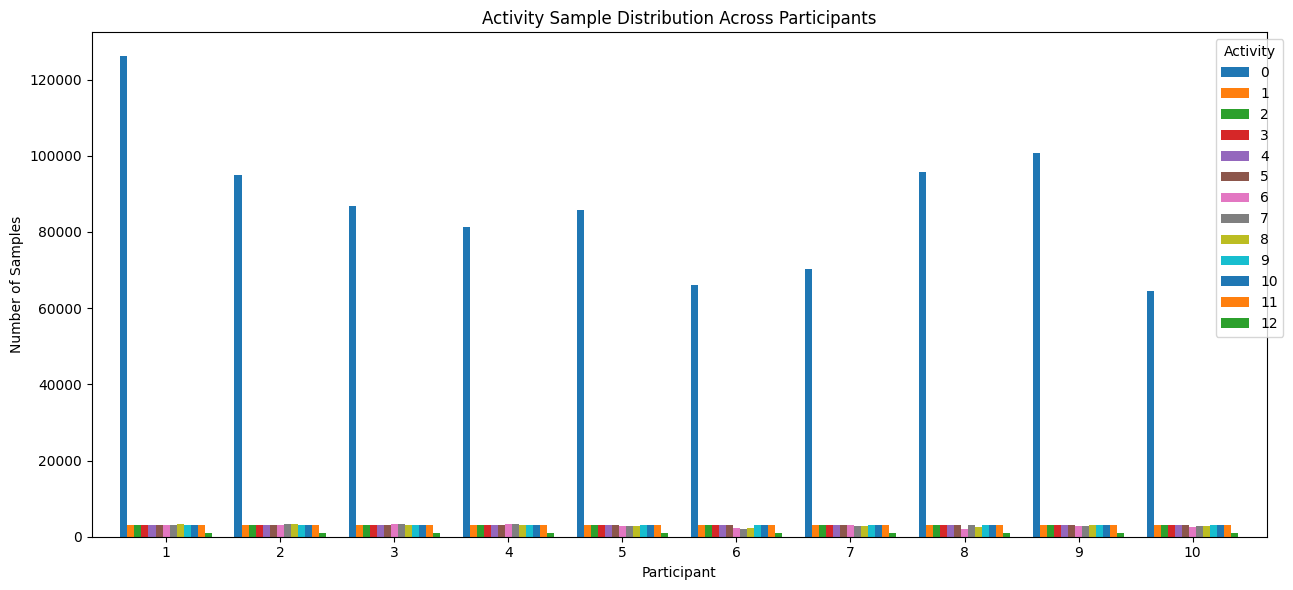

In [15]:
activity_distribution.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Activity Sample Distribution Across Participants")
plt.xlabel("Participant")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend(title="Activity", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [16]:
# Identify consecutive segments of the same activity
segments = []

for participant in sorted(raw_data["participant"].unique()):

    participant_df = raw_data[
        raw_data["participant"] == participant
    ].reset_index(drop=True)

    # Assign a new segment whenever the activity changes
    segment_ids = (
        participant_df["activity"]
        .ne(participant_df["activity"].shift())
        .cumsum()
    )

    for segment_id, group in participant_df.groupby(segment_ids):

        segments.append({
            "participant": participant,
            "activity": int(group["activity"].iloc[0]),
            "start_sample": int(group.index[0]),
            "end_sample": int(group.index[-1]),
            "samples": len(group),
            "duration_seconds": len(group) / 50
        })

segments_df = pd.DataFrame(segments)

# Display selected activities and null segments
selected_segments = segments_df[
    segments_df["activity"].isin([0, 1, 7, 8])
]

display(
    selected_segments.round(2)
)

print("\nNUMBER OF CONTINUOUS SEGMENTS")
display(
    selected_segments.groupby(
        ["participant", "activity"]
    ).size().unstack(fill_value=0)
)

,participant,activity,start_sample,end_sample,samples,duration_seconds
0,1,0,0,6655,6656,133.12
1,1,1,6656,9727,3072,61.44
2,1,0,9728,12799,3072,61.44
4,1,0,15872,18943,3072,61.44
6,1,0,22016,28159,6144,122.88
...,...,...,...,...,...,...
253,10,0,61287,69375,8089,161.78
255,10,0,72448,75263,2816,56.32
257,10,0,78336,81407,3072,61.44
259,10,0,84480,95180,10701,214.02



NUMBER OF CONTINUOUS SEGMENTS


activity,0,1,7,8
participant,,,,
1,13,1,1,1
2,13,1,1,1
3,13,1,1,1
4,13,1,1,1
5,13,1,1,1
6,13,1,1,1
7,18,1,1,1
8,14,1,1,1
9,13,1,1,1


In [17]:
# Keep only our selected activities
movement_segments = segments_df[
    segments_df["activity"].isin([1, 7, 8])
].copy()

# Add readable activity names
activity_names = {
    1: "Standing",
    7: "Arm elevation",
    8: "Knee bending"
}

movement_segments["activity_name"] = (
    movement_segments["activity"].map(activity_names)
)

# Sort chronologically within each participant
movement_segments = movement_segments.sort_values(
    ["participant", "start_sample"]
)

# Display relevant information
display(
    movement_segments[
        [
            "participant",
            "activity_name",
            "start_sample",
            "end_sample",
            "samples",
            "duration_seconds"
        ]
    ].round(2).reset_index(drop=True)
)

# Check that every participant has exactly one segment per activity
print("\nSEGMENT COUNT CHECK")

display(
    movement_segments.groupby(
        ["participant", "activity_name"]
    ).size().unstack(fill_value=0)
)

,participant,activity_name,start_sample,end_sample,samples,duration_seconds
0,1,Standing,6656,9727,3072,61.44
1,1,Arm elevation,52736,55807,3072,61.44
2,1,Knee bending,61440,64818,3379,67.58
3,2,Standing,43776,46847,3072,61.44
4,2,Arm elevation,78592,81919,3328,66.56
5,2,Knee bending,83968,87397,3430,68.60
6,3,Standing,4608,7679,3072,61.44
7,3,Arm elevation,41472,44850,3379,67.58
8,3,Knee bending,46284,49458,3175,63.50
9,4,Standing,40192,43263,3072,61.44



SEGMENT COUNT CHECK


activity_name,Arm elevation,Knee bending,Standing
participant,,,
1,1,1,1
2,1,1,1
3,1,1,1
4,1,1,1
5,1,1,1
6,1,1,1
7,1,1,1
8,1,1,1
9,1,1,1


In [18]:
# Window configuration
sampling_rate = 50
window_size = 100  # 2 seconds

# Selected activities
selected_activities = [1, 7, 8]

# Selected right-lower-arm sensors
sensor_columns = [
    "arm_acc_x",
    "arm_acc_y",
    "arm_acc_z",
    "arm_gyro_x",
    "arm_gyro_y",
    "arm_gyro_z"
]

# Store extracted windows
feature_rows = []

# Keep only the three selected activities
selected_segments = segments_df[
    segments_df["activity"].isin(selected_activities)
].copy()

for _, segment in selected_segments.iterrows():

    participant = int(segment["participant"])
    activity = int(segment["activity"])

    # Retrieve the participant's original recording
    participant_df = raw_data[
        raw_data["participant"] == participant
    ].reset_index(drop=True)

    # Extract only this activity segment
    activity_data = participant_df.iloc[
        int(segment["start_sample"]):
        int(segment["end_sample"]) + 1
    ]

    # Divide the segment into non-overlapping 2-second windows
    for start in range(
        0,
        len(activity_data) - window_size + 1,
        window_size
    ):

        window = activity_data.iloc[
            start:start + window_size
        ]

        row = {
            "participant": participant,
            "activity": activity,
            "start_sample": (
                int(segment["start_sample"]) + start
            )
        }

        # Extract five features from each sensor channel
        for sensor in sensor_columns:

            values = window[sensor].to_numpy()

            row[sensor + "_mean"] = np.mean(values)
            row[sensor + "_std"] = np.std(values)
            row[sensor + "_min"] = np.min(values)
            row[sensor + "_max"] = np.max(values)
            row[sensor + "_range"] = np.ptp(values)

        feature_rows.append(row)

# Create the feature dataset
data = pd.DataFrame(feature_rows)

# Add readable activity names
activity_names = {
    1: "Standing",
    7: "Arm elevation",
    8: "Knee bending"
}

data["activity_name"] = data["activity"].map(activity_names)

print("WINDOW EXTRACTION COMPLETE")
print("Total windows:", len(data))
print("Total features:", len(sensor_columns) * 5)
print("Participants:", data["participant"].nunique())

display(data.head())

WINDOW EXTRACTION COMPLETE
Total windows: 877
Total features: 30
Participants: 10


,participant,activity,start_sample,arm_acc_x_mean,arm_acc_x_std,arm_acc_x_min,arm_acc_x_max,arm_acc_x_range,arm_acc_y_mean,arm_acc_y_std,arm_acc_y_min,arm_acc_y_max,arm_acc_y_range,arm_acc_z_mean,arm_acc_z_std,arm_acc_z_min,arm_acc_z_max,arm_acc_z_range,arm_gyro_x_mean,arm_gyro_x_std,arm_gyro_x_min,arm_gyro_x_max,arm_gyro_x_range,arm_gyro_y_mean,arm_gyro_y_std,arm_gyro_y_min,arm_gyro_y_max,arm_gyro_y_range,arm_gyro_z_mean,arm_gyro_z_std,arm_gyro_z_min,arm_gyro_z_max,arm_gyro_z_range,activity_name
0,1,1,6656,-2.857178,0.101645,-3.1087,-2.6157,0.4930,-9.159075,0.103606,-9.4535,-8.9017,0.5518,1.732255,0.111649,1.4767,2.0668,0.5901,-0.065490,0.008065,-0.078431,-0.045098,0.033333,-0.934640,0.009401,-0.96304,-0.91581,0.04723,-0.348771,0.009223,-0.36853,-0.33190,0.03663,Standing
1,1,1,6756,-2.889756,0.113977,-3.1780,-2.5823,0.5957,-9.129484,0.096239,-9.3314,-8.8917,0.4397,1.761650,0.100206,1.4812,2.0614,0.5802,-0.069392,0.007789,-0.086275,-0.056863,0.029412,-0.937064,0.007638,-0.95483,-0.92197,0.03286,-0.344505,0.007784,-0.36422,-0.32759,0.03663,Standing
2,1,1,6856,-2.927922,0.150274,-3.4133,-2.5602,0.8531,-9.112184,0.108323,-9.4541,-8.8420,0.6121,1.761369,0.102533,1.4996,2.0460,0.5464,-0.064765,0.007576,-0.080392,-0.047059,0.033333,-0.938501,0.008976,-0.95893,-0.92197,0.03696,-0.339957,0.008904,-0.36207,-0.32328,0.03879,Standing
3,1,1,6956,-2.866276,0.098205,-3.1093,-2.5878,0.5215,-9.149314,0.102669,-9.4238,-8.9148,0.5090,1.688887,0.104304,1.3498,1.9706,0.6208,-0.060941,0.006130,-0.074510,-0.047059,0.027451,-0.936590,0.008277,-0.95277,-0.91992,0.03285,-0.349396,0.008887,-0.37284,-0.32974,0.04310,Standing
4,1,1,7056,-2.956062,0.113393,-3.2689,-2.6776,0.5913,-9.140876,0.101015,-9.3735,-8.8531,0.5204,1.662330,0.118820,1.3611,2.0148,0.6537,-0.062647,0.008029,-0.076471,-0.047059,0.029412,-0.934886,0.007210,-0.95072,-0.91786,0.03286,-0.351832,0.006906,-0.36422,-0.33836,0.02586,Standing


In [19]:
# Windows per activity
print("WINDOWS PER ACTIVITY")

display(
    data["activity_name"]
    .value_counts()
    .to_frame("window_count")
)

# Windows per participant and activity
print("\nWINDOWS PER PARTICIPANT")

display(
    data.groupby(
        ["participant", "activity_name"]
    ).size().unstack(fill_value=0)
)

# Check missing values
print("\nMISSING VALUES:", data.isnull().sum().sum())

# Check feature count
feature_columns = [
    col for col in data.columns
    if col.endswith(
        ("_mean", "_std", "_min", "_max", "_range")
    )
]

print("FEATURE COUNT:", len(feature_columns))

WINDOWS PER ACTIVITY


,window_count
activity_name,
Standing,300
Knee bending,289
Arm elevation,288



WINDOWS PER PARTICIPANT


activity_name,Arm elevation,Knee bending,Standing
participant,,,
1,30,33,30
2,33,34,30
3,33,31,30
4,32,31,30
5,28,27,30
6,20,23,30
7,27,28,30
8,30,25,30
9,28,29,30



MISSING VALUES: 0
FEATURE COUNT: 30


In [20]:
evaluation_splits = {}

for participant in sorted(data["participant"].unique()):

    participant_data = data[
        data["participant"] == participant
    ]

    calibration_indices = []
    test_indices = []

    for activity in selected_activities:

        activity_data = participant_data[
            participant_data["activity"] == activity
        ].sort_values("start_sample")

        indices = activity_data.index.to_list()

        n = len(indices)
        calibration_count = int(n * 0.30)
        gap_count = 5

        if calibration_count + gap_count + 2 > n:
            raise ValueError(
                f"Insufficient windows: participant {participant}, "
                f"activity {activity}"
            )

        calibration_indices.extend(
            indices[:calibration_count]
        )

        test_indices.extend(
            indices[calibration_count + gap_count:]
        )

    calibration_data = data.loc[calibration_indices].copy()
    test_data = data.loc[test_indices].copy()

    other_data = data[
        data["participant"] != participant
    ].copy()

    evaluation_splits[participant] = {
        "other_data": other_data,
        "calibration_data": calibration_data,
        "test_data": test_data
    }

print("SPLIT CONSTRUCTION COMPLETE")

SPLIT CONSTRUCTION COMPLETE


In [22]:
split_summary = []

for participant, split in evaluation_splits.items():

    calibration = split["calibration_data"]
    testing = split["test_data"]

    for activity in selected_activities:

        calibration_count = (
            calibration["activity"] == activity
        ).sum()

        test_count = (
            testing["activity"] == activity
        ).sum()

        split_summary.append({
            "participant": participant,
            "activity": activity,
            "calibration_windows": calibration_count,
            "test_windows": test_count
        })

split_summary_df = pd.DataFrame(split_summary)

display(split_summary_df)

print("\nTOTAL CALIBRATION WINDOWS:",
      sum(len(s["calibration_data"]) for s in evaluation_splits.values()))

print("TOTAL TEST WINDOWS:",
      sum(len(s["test_data"]) for s in evaluation_splits.values()))

,participant,activity,calibration_windows,test_windows
0,1,1,9,16
1,1,7,9,16
2,1,8,9,19
3,2,1,9,16
4,2,7,9,19
5,2,8,10,19
6,3,1,9,16
7,3,7,9,19
8,3,8,9,17
9,4,1,9,16



TOTAL CALIBRATION WINDOWS: 255
TOTAL TEST WINDOWS: 472


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Identify the 30 numerical features
feature_columns = [
    col for col in data.columns
    if col.endswith(
        ("_mean", "_std", "_min", "_max", "_range")
    )
]

results = []
predictions_by_participant = {}

for participant, split in evaluation_splits.items():

    other_data = split["other_data"]
    calibration_data = split["calibration_data"]
    test_data = split["test_data"]

    # Verify participant separation
    assert participant not in other_data["participant"].unique()

    # Verify that calibration and testing are disjoint
    assert set(calibration_data.index).isdisjoint(
        set(test_data.index)
    )

    X_test = test_data[feature_columns]
    y_test = test_data["activity"]

    # -------------------------
    # GENERAL MODEL
    # -------------------------

    general_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    general_model.fit(
        other_data[feature_columns],
        other_data["activity"]
    )

    general_pred = general_model.predict(X_test)

    # -------------------------
    # PERSONALISED MODEL
    # -------------------------

    personalised_training = pd.concat(
        [other_data, calibration_data]
    )

    personalised_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    personalised_model.fit(
        personalised_training[feature_columns],
        personalised_training["activity"]
    )

    personalised_pred = personalised_model.predict(X_test)

    # -------------------------
    # EVALUATION
    # -------------------------

    general_accuracy = accuracy_score(
        y_test, general_pred
    )

    personal_accuracy = accuracy_score(
        y_test, personalised_pred
    )

    general_balanced = balanced_accuracy_score(
        y_test, general_pred
    )

    personal_balanced = balanced_accuracy_score(
        y_test, personalised_pred
    )

    general_f1 = f1_score(
        y_test, general_pred,
        average="macro"
    )

    personal_f1 = f1_score(
        y_test, personalised_pred,
        average="macro"
    )

    results.append({
        "participant": participant,
        "test_windows": len(test_data),

        "general_accuracy": general_accuracy * 100,
        "personalised_accuracy": personal_accuracy * 100,

        "general_balanced_accuracy": general_balanced * 100,
        "personalised_balanced_accuracy": personal_balanced * 100,

        "general_macro_f1": general_f1 * 100,
        "personalised_macro_f1": personal_f1 * 100,

        "accuracy_change": (
            personal_accuracy - general_accuracy
        ) * 100
    })

    predictions_by_participant[participant] = {
        "actual": y_test.to_numpy(),
        "general": general_pred,
        "personalised": personalised_pred
    }

    print(f"Completed participant {participant}/10")

# Create results table
results_df = pd.DataFrame(results)

print("\nMODEL EVALUATION COMPLETE")
display(results_df.round(2))

Completed participant 1/10
Completed participant 2/10
Completed participant 3/10
Completed participant 4/10
Completed participant 5/10
Completed participant 6/10
Completed participant 7/10
Completed participant 8/10
Completed participant 9/10
Completed participant 10/10

MODEL EVALUATION COMPLETE


,participant,test_windows,general_accuracy,personalised_accuracy,general_balanced_accuracy,personalised_balanced_accuracy,general_macro_f1,personalised_macro_f1,accuracy_change
0,1,51,100.00,100.00,100.00,100.00,100.00,100.00,0.0
1,2,54,98.15,98.15,98.25,98.25,98.24,98.24,0.0
2,3,52,100.00,100.00,100.00,100.00,100.00,100.00,0.0
3,4,51,100.00,100.00,100.00,100.00,100.00,100.00,0.0
4,5,45,100.00,100.00,100.00,100.00,100.00,100.00,0.0
5,6,37,100.00,100.00,100.00,100.00,100.00,100.00,0.0
6,7,45,100.00,100.00,100.00,100.00,100.00,100.00,0.0
7,8,45,100.00,100.00,100.00,100.00,100.00,100.00,0.0
8,9,47,100.00,100.00,100.00,100.00,100.00,100.00,0.0
9,10,45,100.00,100.00,100.00,100.00,100.00,100.00,0.0


In [24]:
metrics = [
    "general_accuracy",
    "personalised_accuracy",
    "general_balanced_accuracy",
    "personalised_balanced_accuracy",
    "general_macro_f1",
    "personalised_macro_f1",
    "accuracy_change"
]

print("MEAN PARTICIPANT PERFORMANCE")

display(
    results_df[metrics].mean().to_frame(
        "Mean percentage"
    ).round(2)
)

print("\nMEDIAN PARTICIPANT PERFORMANCE")

display(
    results_df[metrics].median().to_frame(
        "Median percentage"
    ).round(2)
)

MEAN PARTICIPANT PERFORMANCE


,Mean percentage
general_accuracy,99.81
personalised_accuracy,99.81
general_balanced_accuracy,99.82
personalised_balanced_accuracy,99.82
general_macro_f1,99.82
personalised_macro_f1,99.82
accuracy_change,0.00



MEDIAN PARTICIPANT PERFORMANCE


,Median percentage
general_accuracy,100.0
personalised_accuracy,100.0
general_balanced_accuracy,100.0
personalised_balanced_accuracy,100.0
general_macro_f1,100.0
personalised_macro_f1,100.0
accuracy_change,0.0


In [25]:
for participant, predictions in predictions_by_participant.items():

    general = predictions["general"]
    personal = predictions["personalised"]
    actual = predictions["actual"]

    print(f"\nParticipant {participant}")
    print("Test windows:", len(actual))
    print(
        "General correct:",
        np.sum(general == actual)
    )
    print(
        "Personalised correct:",
        np.sum(personal == actual)
    )
    print(
        "Predictions identical:",
        np.array_equal(general, personal)
    )
    print(
        "Predictions changed:",
        np.sum(general != personal)
    )


Participant 1
Test windows: 51
General correct: 51
Personalised correct: 51
Predictions identical: True
Predictions changed: 0

Participant 2
Test windows: 54
General correct: 53
Personalised correct: 53
Predictions identical: True
Predictions changed: 0

Participant 3
Test windows: 52
General correct: 52
Personalised correct: 52
Predictions identical: True
Predictions changed: 0

Participant 4
Test windows: 51
General correct: 51
Personalised correct: 51
Predictions identical: True
Predictions changed: 0

Participant 5
Test windows: 45
General correct: 45
Personalised correct: 45
Predictions identical: True
Predictions changed: 0

Participant 6
Test windows: 37
General correct: 37
Personalised correct: 37
Predictions identical: True
Predictions changed: 0

Participant 7
Test windows: 45
General correct: 45
Personalised correct: 45
Predictions identical: True
Predictions changed: 0

Participant 8
Test windows: 45
General correct: 45
Personalised correct: 45
Predictions identical: True

In [26]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

rng = np.random.default_rng(42)

negative_control_results = []

for participant, split in evaluation_splits.items():

    train = split["other_data"]
    test = split["test_data"]

    X_train = train[feature_columns]
    y_train = train["activity"].to_numpy()

    X_test = test[feature_columns]
    y_test = test["activity"].to_numpy()

    for repetition in range(20):

        # Randomly shuffle training labels
        shuffled_labels = rng.permutation(y_train)

        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            class_weight="balanced",
            random_state=42
        )

        model.fit(X_train, shuffled_labels)

        predictions = model.predict(X_test)

        negative_control_results.append({
            "participant": participant,
            "repetition": repetition,
            "accuracy": accuracy_score(
                y_test, predictions
            ) * 100
        })

negative_control_df = pd.DataFrame(
    negative_control_results
)

print("NEGATIVE CONTROL RESULTS")

print(
    "Mean accuracy:",
    round(negative_control_df["accuracy"].mean(), 2)
)

print(
    "Minimum accuracy:",
    round(negative_control_df["accuracy"].min(), 2)
)

print(
    "Maximum accuracy:",
    round(negative_control_df["accuracy"].max(), 2)
)

NEGATIVE CONTROL RESULTS
Mean accuracy: 33.28
Minimum accuracy: 0.0
Maximum accuracy: 100.0


In [27]:
from sklearn.dummy import DummyClassifier

baseline_results = []

for participant, split in evaluation_splits.items():

    train = split["other_data"]
    test = split["test_data"]

    baseline = DummyClassifier(
        strategy="most_frequent"
    )

    baseline.fit(
        train[feature_columns],
        train["activity"]
    )

    predictions = baseline.predict(
        test[feature_columns]
    )

    baseline_results.append({
        "participant": participant,
        "baseline_accuracy": accuracy_score(
            test["activity"], predictions
        ) * 100
    })

baseline_df = pd.DataFrame(baseline_results)

print("BASELINE MEAN ACCURACY:",
      round(baseline_df["baseline_accuracy"].mean(), 2))

display(baseline_df.round(2))

BASELINE MEAN ACCURACY: 34.27


,participant,baseline_accuracy
0,1,31.37
1,2,29.63
2,3,30.77
3,4,31.37
4,5,35.56
5,6,43.24
6,7,35.56
7,8,35.56
8,9,34.04
9,10,35.56


In [28]:
# Compare average sensor features across activities

activity_feature_means = data.groupby("activity")[feature_columns].mean()

activity_names = {
    1: "Standing",
    7: "Arm elevation",
    8: "Knee bending"
}

activity_feature_means.index = [
    activity_names[i] for i in activity_feature_means.index
]

display(activity_feature_means.round(3))

,arm_acc_x_mean,arm_acc_x_std,arm_acc_x_min,arm_acc_x_max,arm_acc_x_range,arm_acc_y_mean,arm_acc_y_std,arm_acc_y_min,arm_acc_y_max,arm_acc_y_range,arm_acc_z_mean,arm_acc_z_std,arm_acc_z_min,arm_acc_z_max,arm_acc_z_range,arm_gyro_x_mean,arm_gyro_x_std,arm_gyro_x_min,arm_gyro_x_max,arm_gyro_x_range,arm_gyro_y_mean,arm_gyro_y_std,arm_gyro_y_min,arm_gyro_y_max,arm_gyro_y_range,arm_gyro_z_mean,arm_gyro_z_std,arm_gyro_z_min,arm_gyro_z_max,arm_gyro_z_range
Standing,-2.440,0.137,-2.801,-2.068,0.733,-9.304,0.114,-9.596,-9.002,0.594,1.138,0.129,0.796,1.465,0.670,-0.340,0.009,-0.359,-0.322,0.037,-0.746,0.009,-0.765,-0.729,0.036,0.172,0.011,0.149,0.194,0.044
Arm elevation,-1.332,2.534,-7.357,3.079,10.436,-2.371,6.636,-12.664,7.477,20.141,5.188,2.186,0.875,10.332,9.457,-0.165,0.171,-0.435,0.106,0.541,-0.092,0.523,-0.851,0.590,1.442,0.532,0.371,-0.067,1.008,1.075
Knee bending,-1.552,1.138,-4.858,1.491,6.348,-9.371,2.113,-14.764,-5.196,9.568,1.222,1.124,-1.582,4.552,6.134,-0.124,0.079,-0.254,0.012,0.266,-0.862,0.051,-0.948,-0.774,0.174,0.046,0.107,-0.127,0.222,0.349


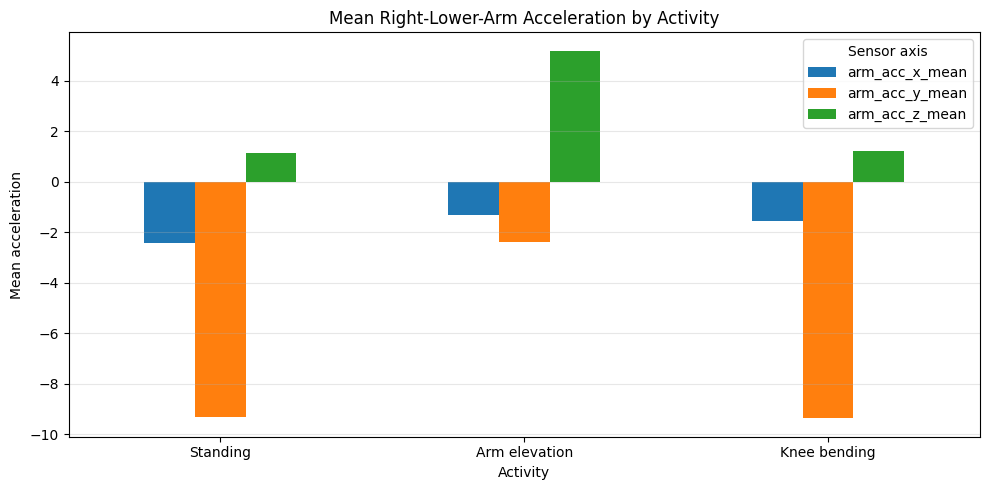

In [29]:
# Plot mean acceleration measurements for each activity

acceleration_features = [
    "arm_acc_x_mean",
    "arm_acc_y_mean",
    "arm_acc_z_mean"
]

activity_feature_means[acceleration_features].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Mean Right-Lower-Arm Acceleration by Activity")
plt.xlabel("Activity")
plt.ylabel("Mean acceleration")
plt.xticks(rotation=0)
plt.legend(title="Sensor axis")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
rng = np.random.default_rng(42)

perfect_cases = []

for participant, split in evaluation_splits.items():

    train = split["other_data"]
    test = split["test_data"]

    X_train = train[feature_columns]
    y_train = train["activity"].to_numpy()

    X_test = test[feature_columns]
    y_test = test["activity"].to_numpy()

    for repetition in range(20):

        shuffled_labels = rng.permutation(y_train)

        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            class_weight="balanced",
            random_state=42
        )

        model.fit(X_train, shuffled_labels)
        predictions = model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        if accuracy == 1.0:
            perfect_cases.append({
                "participant": participant,
                "repetition": repetition,
                "test_labels": y_test.copy(),
                "predictions": predictions.copy()
            })

print("Number of perfect cases:", len(perfect_cases))

for case in perfect_cases:

    print("\nParticipant:", case["participant"])
    print("Repetition:", case["repetition"])

    print("Actual class counts:")
    print(pd.Series(case["test_labels"]).value_counts().sort_index())

    print("Predicted class counts:")
    print(pd.Series(case["predictions"]).value_counts().sort_index())

Number of perfect cases: 1

Participant: 1
Repetition: 12
Actual class counts:
1    16
7    16
8    19
Name: count, dtype: int64
Predicted class counts:
1    16
7    16
8    19
Name: count, dtype: int64


In [31]:
# Inspect the feature columns
print("FEATURE COLUMNS:")
print(feature_columns)

print("\nPossible label leakage:")
print([
    col for col in feature_columns
    if col in ["activity", "activity_name", "participant", "start_sample"]
])

# Reproduce participant 1, repetition 12
participant = 1
split = evaluation_splits[participant]

train = split["other_data"]
test = split["test_data"]

X_train = train[feature_columns]
y_train = train["activity"].to_numpy()

X_test = test[feature_columns]
y_test = test["activity"].to_numpy()

rng = np.random.default_rng(42)

for repetition in range(13):
    shuffled_labels = rng.permutation(y_train)

print("\nOriginal training label counts:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nShuffled training label counts:")
print(pd.Series(shuffled_labels).value_counts().sort_index())

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, shuffled_labels)
predictions = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, predictions))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions, labels=[1, 7, 8]))

print("\nActual and predicted labels:")
print(pd.DataFrame({
    "actual": y_test,
    "predicted": predictions,
    "correct": y_test == predictions
}).to_string(index=False))

FEATURE COLUMNS:
['arm_acc_x_mean', 'arm_acc_x_std', 'arm_acc_x_min', 'arm_acc_x_max', 'arm_acc_x_range', 'arm_acc_y_mean', 'arm_acc_y_std', 'arm_acc_y_min', 'arm_acc_y_max', 'arm_acc_y_range', 'arm_acc_z_mean', 'arm_acc_z_std', 'arm_acc_z_min', 'arm_acc_z_max', 'arm_acc_z_range', 'arm_gyro_x_mean', 'arm_gyro_x_std', 'arm_gyro_x_min', 'arm_gyro_x_max', 'arm_gyro_x_range', 'arm_gyro_y_mean', 'arm_gyro_y_std', 'arm_gyro_y_min', 'arm_gyro_y_max', 'arm_gyro_y_range', 'arm_gyro_z_mean', 'arm_gyro_z_std', 'arm_gyro_z_min', 'arm_gyro_z_max', 'arm_gyro_z_range']

Possible label leakage:
[]

Original training label counts:
1    270
7    258
8    256
Name: count, dtype: int64

Shuffled training label counts:
1    270
7    258
8    256
Name: count, dtype: int64

Accuracy: 1.0

Confusion matrix:
[[16  0  0]
 [ 0 16  0]
 [ 0  0 19]]

Actual and predicted labels:
 actual  predicted  correct
      1          1     True
      1          1     True
      1          1     True
      1          1     Tru

In [32]:
participant = 1
split = evaluation_splits[participant]

train = split["other_data"]
calibration = split["calibration_data"]
test = split["test_data"]

print("TARGET PARTICIPANT:", participant)

print("\nParticipants in training data:")
print(sorted(train["participant"].unique()))

print("\nParticipants in calibration data:")
print(sorted(calibration["participant"].unique()))

print("\nParticipants in test data:")
print(sorted(test["participant"].unique()))

print("\nDoes training contain target participant?")
print(participant in train["participant"].unique())

print("\nDoes test contain only target participant?")
print(test["participant"].nunique() == 1)

# Check whether original DataFrame row indices overlap
print("\nTRAIN / TEST INDEX OVERLAP:")
print(len(set(train.index) & set(test.index)))

print("\nCALIBRATION / TEST INDEX OVERLAP:")
print(len(set(calibration.index) & set(test.index)))

# Check for identical feature rows across training and test
train_features = train[feature_columns]
test_features = test[feature_columns]

train_tuples = set(map(tuple, train_features.to_numpy()))
test_tuples = set(map(tuple, test_features.to_numpy()))

print("\nIDENTICAL FEATURE ROWS:")
print(len(train_tuples & test_tuples))

TARGET PARTICIPANT: 1

Participants in training data:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Participants in calibration data:
[np.int64(1)]

Participants in test data:
[np.int64(1)]

Does training contain target participant?
False

Does test contain only target participant?
True

TRAIN / TEST INDEX OVERLAP:
0

CALIBRATION / TEST INDEX OVERLAP:
0

IDENTICAL FEATURE ROWS:
0


In [33]:
# Check relationship between original and shuffled labels

print("Original vs shuffled training labels:")
print(pd.crosstab(
    train["activity"],
    shuffled_labels,
    rownames=["Original activity"],
    colnames=["Shuffled label"]
))

print("\nCorrelation between original and shuffled labels:")
print(np.corrcoef(
    train["activity"].to_numpy(),
    shuffled_labels
)[0, 1])

# Check model performance on its shuffled training labels
train_predictions = model.predict(X_train)

print("\nTraining accuracy against shuffled labels:")
print(accuracy_score(shuffled_labels, train_predictions))

# Check model performance on the untouched test labels
print("\nTest accuracy against actual labels:")
print(accuracy_score(y_test, predictions))


Original vs shuffled training labels:
Shuffled label      1    7    8
Original activity              
1                  93   77  100
7                  85  102   71
8                  92   79   85

Correlation between original and shuffled labels:
-0.012111353588713288

Training accuracy against shuffled labels:
0.9387755102040817

Test accuracy against actual labels:
1.0


In [34]:
# Fresh negative-control experiment for participant 1

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

target = 1

fresh_train = evaluation_splits[target]["other_data"].copy()
fresh_test = evaluation_splits[target]["test_data"].copy()

# Reset indices to make alignment explicit
fresh_train = fresh_train.reset_index(drop=True)
fresh_test = fresh_test.reset_index(drop=True)

fresh_X_train = fresh_train[feature_columns].copy()
fresh_y_train = fresh_train["activity"].to_numpy().copy()

fresh_X_test = fresh_test[feature_columns].copy()
fresh_y_test = fresh_test["activity"].to_numpy().copy()

# Generate a fresh random permutation
fresh_rng = np.random.default_rng(2026)
fresh_shuffled_y = fresh_rng.permutation(fresh_y_train)

# Train a completely new model
fresh_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

fresh_model.fit(fresh_X_train, fresh_shuffled_y)

# Evaluate
fresh_train_predictions = fresh_model.predict(fresh_X_train)
fresh_test_predictions = fresh_model.predict(fresh_X_test)

print("TRAINING SAMPLES:", len(fresh_y_train))
print("TEST SAMPLES:", len(fresh_y_test))

print("\nOriginal vs shuffled labels:")
print(pd.crosstab(fresh_y_train, fresh_shuffled_y))

print("\nShuffled-label training accuracy:")
print(accuracy_score(fresh_shuffled_y, fresh_train_predictions))

print("\nActual-label test accuracy:")
print(accuracy_score(fresh_y_test, fresh_test_predictions))

print("\nPredicted test class counts:")
print(pd.Series(fresh_test_predictions).value_counts().sort_index())

print("\nActual test class counts:")
print(pd.Series(fresh_y_test).value_counts().sort_index())

TRAINING SAMPLES: 784
TEST SAMPLES: 51

Original vs shuffled labels:
col_0    1    7   8
row_0              
1       85  102  83
7      104   74  80
8       81   82  93

Shuffled-label training accuracy:
0.9579081632653061

Actual-label test accuracy:
0.1568627450980392

Predicted test class counts:
1    18
7    17
8    16
Name: count, dtype: int64

Actual test class counts:
1    16
7    16
8    19
Name: count, dtype: int64


In [35]:
rng = np.random.default_rng(20261121)

negative_control_1 = []

for repetition in range(200):

    shuffled_y = rng.permutation(fresh_y_train)

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    model.fit(fresh_X_train, shuffled_y)

    predictions = model.predict(fresh_X_test)

    negative_control_1.append(
        accuracy_score(fresh_y_test, predictions) * 100
    )

negative_control_1 = np.array(negative_control_1)

print("MEAN:", negative_control_1.mean())
print("MEDIAN:", np.median(negative_control_1))
print("MINIMUM:", negative_control_1.min())
print("MAXIMUM:", negative_control_1.max())

print("PERFECT RESULTS:", np.sum(negative_control_1 == 100))

print("\nAccuracy distribution:")
print(pd.Series(negative_control_1).describe())

MEAN: 32.754901960784316
MEDIAN: 31.372549019607842
MINIMUM: 1.9607843137254901
MAXIMUM: 82.35294117647058
PERFECT RESULTS: 0

Accuracy distribution:
count    200.000000
mean      32.754902
std       16.268861
min        1.960784
25%       21.568627
50%       31.372549
75%       43.137255
max       82.352941
dtype: float64


In [36]:
# Feature importance for the general model, participant 1

target = 1
split = evaluation_splits[target]

train = split["other_data"]

X_train = train[feature_columns]
y_train = train["activity"]

importance_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

importance_model.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": importance_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

print(feature_importance.head(15).to_string(index=False))

         feature  importance
   arm_acc_y_max    0.158777
   arm_acc_y_std    0.152261
arm_gyro_y_range    0.101568
  arm_gyro_y_max    0.092476
  arm_gyro_y_std    0.086464
 arm_acc_y_range    0.059957
   arm_acc_z_std    0.055697
   arm_acc_x_std    0.051183
 arm_acc_z_range    0.037234
  arm_acc_y_mean    0.037103
arm_gyro_x_range    0.035089
  arm_gyro_x_std    0.025136
  arm_gyro_z_max    0.022590
arm_gyro_z_range    0.021853
   arm_acc_y_min    0.014383


In [37]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

sensor_groups = {
    "Accelerometer only": [
        col for col in feature_columns
        if "acc" in col
    ],

    "Gyroscope only": [
        col for col in feature_columns
        if "gyro" in col
    ],

    "Both sensors": feature_columns
}

ablation_results = []

for sensor_name, selected_features in sensor_groups.items():

    participant_scores = []

    for participant, split in evaluation_splits.items():

        train = split["other_data"]
        test = split["test_data"]

        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            class_weight="balanced",
            random_state=42
        )

        model.fit(
            train[selected_features],
            train["activity"]
        )

        predictions = model.predict(test[selected_features])

        participant_scores.append({
            "accuracy": accuracy_score(
                test["activity"], predictions
            ) * 100,

            "balanced_accuracy": balanced_accuracy_score(
                test["activity"], predictions
            ) * 100,

            "macro_f1": f1_score(
                test["activity"], predictions,
                average="macro"
            ) * 100
        })

    ablation_results.append({
        "sensor_group": sensor_name,
        "mean_accuracy": np.mean([
            x["accuracy"] for x in participant_scores
        ]),
        "mean_balanced_accuracy": np.mean([
            x["balanced_accuracy"] for x in participant_scores
        ]),
        "mean_macro_f1": np.mean([
            x["macro_f1"] for x in participant_scores
        ])
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(3))

,sensor_group,mean_accuracy,mean_balanced_accuracy,mean_macro_f1
0,Accelerometer only,100.000,100.000,100.000
1,Gyroscope only,98.631,98.673,98.644
2,Both sensors,99.815,99.825,99.824


In [38]:
probability_results = []

for participant, split in evaluation_splits.items():

    general_train = split["other_data"]
    calibration = split["calibration_data"]
    test = split["test_data"]

    X_general = general_train[feature_columns]
    y_general = general_train["activity"]

    X_personal = pd.concat(
        [general_train, calibration]
    )

    X_test = test[feature_columns]
    y_test = test["activity"].to_numpy()

    general_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    personal_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    general_model.fit(X_general, y_general)

    personal_model.fit(
        X_personal[feature_columns],
        X_personal["activity"]
    )

    general_prob = general_model.predict_proba(X_test)
    personal_prob = personal_model.predict_proba(X_test)

    # Align class columns before comparing probabilities
    classes = general_model.classes_

    personal_prob = personal_model.predict_proba(X_test)

    probability_results.append({
        "participant": participant,
        "mean_general_confidence": general_prob.max(axis=1).mean(),
        "mean_personal_confidence": personal_prob.max(axis=1).mean(),
        "mean_probability_difference": np.abs(
            general_prob - personal_prob
        ).mean()
    })

probability_df = pd.DataFrame(probability_results)

display(probability_df.round(4))

,participant,mean_general_confidence,mean_personal_confidence,mean_probability_difference
0,1,0.9802,0.9927,0.0093
1,2,0.9739,0.9783,0.0037
2,3,0.9919,0.9917,0.0021
3,4,0.9810,0.9869,0.0094
4,5,0.9809,0.9987,0.0119
5,6,0.9743,0.9838,0.0063
6,7,0.9944,0.9984,0.0030
7,8,0.9536,0.9967,0.0287
8,9,0.9991,0.9994,0.0001
9,10,0.9889,0.9904,0.0028


In [39]:
from sklearn.metrics import brier_score_loss
from sklearn.preprocessing import label_binarize

brier_results = []

for participant, split in evaluation_splits.items():

    general_train = split["other_data"]
    calibration = split["calibration_data"]
    test = split["test_data"]

    personal_train = pd.concat(
        [general_train, calibration]
    )

    X_test = test[feature_columns]
    y_test = test["activity"].to_numpy()

    general_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    personal_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    general_model.fit(
        general_train[feature_columns],
        general_train["activity"]
    )

    personal_model.fit(
        personal_train[feature_columns],
        personal_train["activity"]
    )

    classes = general_model.classes_

    general_prob = general_model.predict_proba(X_test)
    personal_prob = personal_model.predict_proba(X_test)

    y_binary = label_binarize(y_test, classes=classes)

    general_brier = np.mean(
        np.sum((general_prob - y_binary) ** 2, axis=1)
    )

    personal_brier = np.mean(
        np.sum((personal_prob - y_binary) ** 2, axis=1)
    )

    brier_results.append({
        "participant": participant,
        "general_brier": general_brier,
        "personal_brier": personal_brier,
        "difference": personal_brier - general_brier
    })

brier_df = pd.DataFrame(brier_results)

display(brier_df.round(5))

print("\nMean general Brier score:",
      brier_df["general_brier"].mean())

print("Mean personalised Brier score:",
      brier_df["personal_brier"].mean())

,participant,general_brier,personal_brier,difference
0,1,0.00213,0.00044,-0.00169
1,2,0.02686,0.02282,-0.00404
2,3,0.00055,0.00053,-0.00002
3,4,0.00262,0.00240,-0.00022
4,5,0.00114,0.00004,-0.00110
5,6,0.00375,0.00221,-0.00154
6,7,0.00016,0.00008,-0.00007
7,8,0.00655,0.00010,-0.00645
8,9,0.00004,0.00004,-0.00000
9,10,0.00286,0.00296,0.00009



Mean general Brier score: 0.004665729082505053
Mean personalised Brier score: 0.0031613165318972575


In [40]:
from sklearn.metrics import brier_score_loss
from sklearn.preprocessing import label_binarize

brier_results = []

for participant, split in evaluation_splits.items():

    general_train = split["other_data"]
    calibration = split["calibration_data"]
    test = split["test_data"]

    personal_train = pd.concat(
        [general_train, calibration]
    )

    X_test = test[feature_columns]
    y_test = test["activity"].to_numpy()

    general_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    personal_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    )

    general_model.fit(
        general_train[feature_columns],
        general_train["activity"]
    )

    personal_model.fit(
        personal_train[feature_columns],
        personal_train["activity"]
    )

    classes = general_model.classes_

    general_prob = general_model.predict_proba(X_test)
    personal_prob = personal_model.predict_proba(X_test)

    y_binary = label_binarize(y_test, classes=classes)

    general_brier = np.mean(
        np.sum((general_prob - y_binary) ** 2, axis=1)
    )

    personal_brier = np.mean(
        np.sum((personal_prob - y_binary) ** 2, axis=1)
    )

    brier_results.append({
        "participant": participant,
        "general_brier": general_brier,
        "personal_brier": personal_brier,
        "difference": personal_brier - general_brier
    })

brier_df = pd.DataFrame(brier_results)

display(brier_df.round(5))

print("\nMean general Brier score:",
      brier_df["general_brier"].mean())

print("Mean personalised Brier score:",
      brier_df["personal_brier"].mean())

,participant,general_brier,personal_brier,difference
0,1,0.00213,0.00044,-0.00169
1,2,0.02686,0.02282,-0.00404
2,3,0.00055,0.00053,-0.00002
3,4,0.00262,0.00240,-0.00022
4,5,0.00114,0.00004,-0.00110
5,6,0.00375,0.00221,-0.00154
6,7,0.00016,0.00008,-0.00007
7,8,0.00655,0.00010,-0.00645
8,9,0.00004,0.00004,-0.00000
9,10,0.00286,0.00296,0.00009



Mean general Brier score: 0.004665729082505053
Mean personalised Brier score: 0.0031613165318972575


In [41]:
differences = brier_df["difference"]

print("Mean paired difference:",
      differences.mean())

print("Median paired difference:",
      differences.median())

print("Participants with lower Brier score:",
      (differences < 0).sum())

print("Participants with higher Brier score:",
      (differences > 0).sum())

print("Participants with unchanged Brier score:",
      (differences == 0).sum())

Mean paired difference: -0.0015044125506077951
Median paired difference: -0.0006609150326797392
Participants with lower Brier score: 9
Participants with higher Brier score: 1
Participants with unchanged Brier score: 0


In [42]:
from scipy.stats import binomtest

improvements = (brier_df["difference"] < 0).sum()
worsenings = (brier_df["difference"] > 0).sum()

result = binomtest(
    improvements,
    n=improvements + worsenings,
    p=0.5,
    alternative="greater"
)

print("Participants improved:", improvements)
print("Participants worsened:", worsenings)
print("Sign test p-value:", result.pvalue)

Participants improved: 9
Participants worsened: 1
Sign test p-value: 0.0107421875


In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

FIGURE_FOLDER = "/content/research_figures"

from pathlib import Path
Path(FIGURE_FOLDER).mkdir(exist_ok=True)

print("Figure folder created.")

Figure folder created.


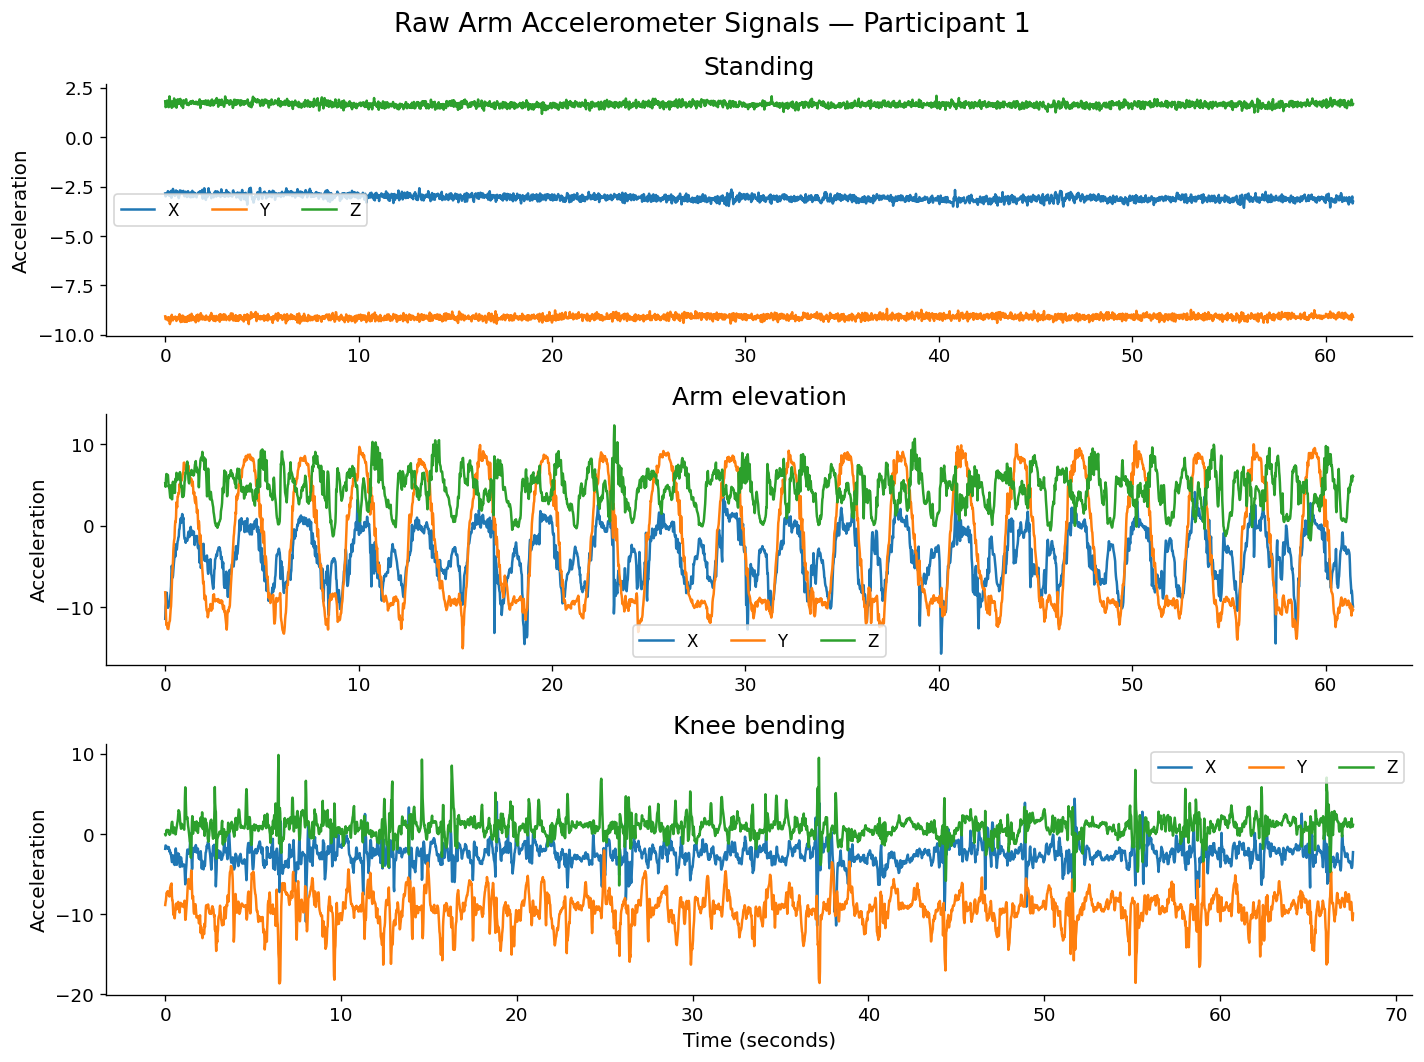

In [44]:
participant_id = 1

plot_data = raw_data[
    (raw_data["participant"] == participant_id) &
    (raw_data["activity"].isin([1, 7, 8]))
].copy()

activity_names = {
    1: "Standing",
    7: "Arm elevation",
    8: "Knee bending"
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for ax, activity in zip(axes, [1, 7, 8]):

    activity_data = plot_data[
        plot_data["activity"] == activity
    ].reset_index(drop=True)

    time = np.arange(len(activity_data)) / 50

    ax.plot(time, activity_data["arm_acc_x"], label="X")
    ax.plot(time, activity_data["arm_acc_y"], label="Y")
    ax.plot(time, activity_data["arm_acc_z"], label="Z")

    ax.set_title(activity_names[activity])
    ax.set_ylabel("Acceleration")
    ax.legend(ncol=3)

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "Raw Arm Accelerometer Signals — Participant 1",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/figure_1_raw_signals.png",
    bbox_inches="tight"
)

plt.show()

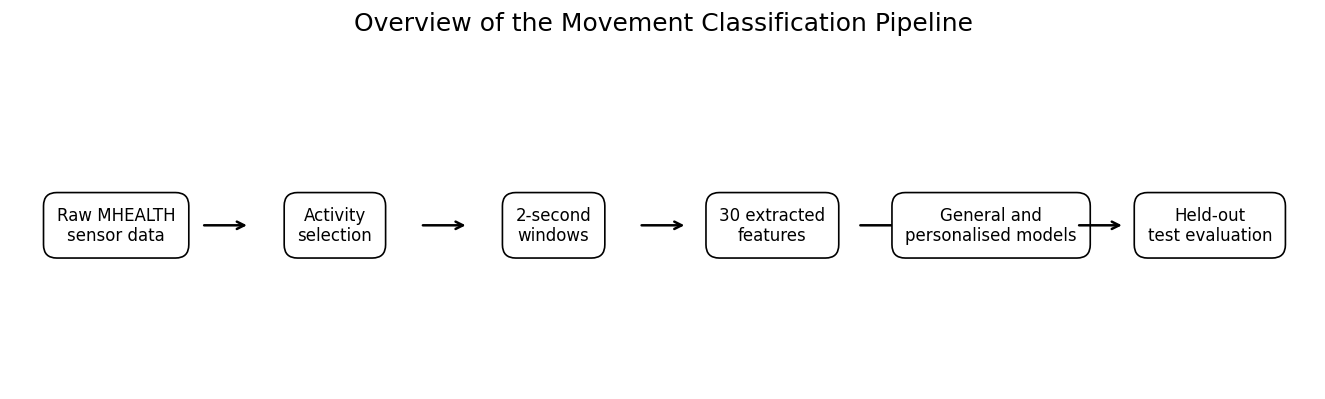

In [45]:
fig, ax = plt.subplots(figsize=(14, 3.5))

ax.axis("off")

steps = [
    "Raw MHEALTH\nsensor data",
    "Activity\nselection",
    "2-second\nwindows",
    "30 extracted\nfeatures",
    "General and\npersonalised models",
    "Held-out\ntest evaluation"
]

x_positions = np.linspace(0.08, 0.92, len(steps))

for i, (x, label) in enumerate(zip(x_positions, steps)):

    ax.text(
        x, 0.5, label,
        ha="center",
        va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.8",
            facecolor="white",
            edgecolor="black"
        ),
        transform=ax.transAxes
    )

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(x_positions[i+1] - 0.065, 0.5),
            xytext=(x + 0.065, 0.5),
            xycoords=ax.transAxes,
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title(
    "Overview of the Movement Classification Pipeline",
    fontsize=15,
    pad=20
)

plt.savefig(
    f"{FIGURE_FOLDER}/figure_2_pipeline.png",
    bbox_inches="tight"
)

plt.show()

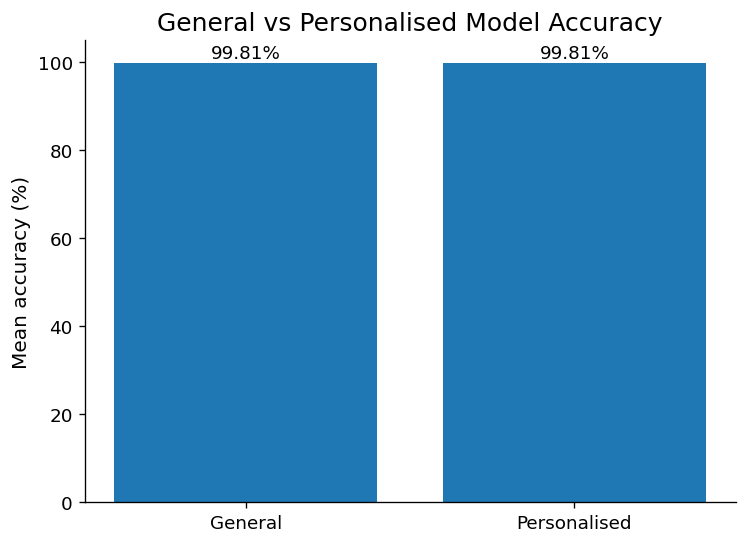

In [46]:
accuracy_data = pd.DataFrame({
    "Model": ["General", "Personalised"],
    "Accuracy": [99.81, 99.81]
})

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    accuracy_data["Model"],
    accuracy_data["Accuracy"]
)

ax.set_ylim(0, 105)
ax.set_ylabel("Mean accuracy (%)")
ax.set_title("General vs Personalised Model Accuracy")

for bar, value in zip(bars, accuracy_data["Accuracy"]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.savefig(
    f"{FIGURE_FOLDER}/figure_3_accuracy.png",
    bbox_inches="tight"
)

plt.show()

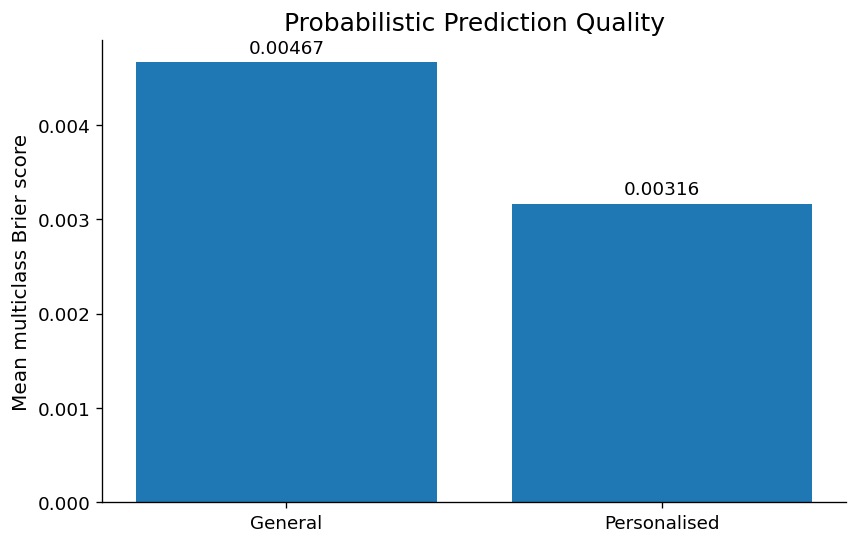

In [47]:
brier_means = [
    brier_df["general_brier"].mean(),
    brier_df["personal_brier"].mean()
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["General", "Personalised"],
    brier_means
)

ax.set_ylabel("Mean multiclass Brier score")
ax.set_title("Probabilistic Prediction Quality")

for bar, value in zip(bars, brier_means):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.0001,
        f"{value:.5f}",
        ha="center"
    )

plt.savefig(
    f"{FIGURE_FOLDER}/figure_4_brier_comparison.png",
    bbox_inches="tight"
)

plt.show()

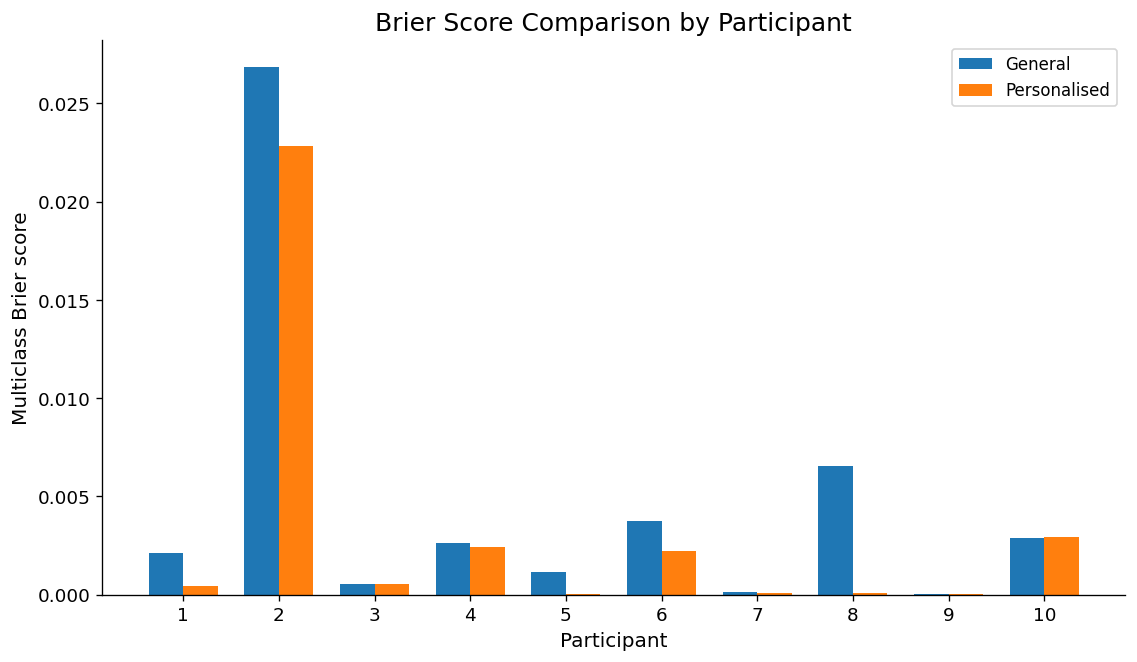

In [48]:
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(brier_df))
width = 0.36

ax.bar(
    x - width/2,
    brier_df["general_brier"],
    width,
    label="General"
)

ax.bar(
    x + width/2,
    brier_df["personal_brier"],
    width,
    label="Personalised"
)

ax.set_xlabel("Participant")
ax.set_ylabel("Multiclass Brier score")
ax.set_title("Brier Score Comparison by Participant")

ax.set_xticks(x)
ax.set_xticklabels(brier_df["participant"])

ax.legend()

plt.savefig(
    f"{FIGURE_FOLDER}/figure_5_participant_brier.png",
    bbox_inches="tight"
)

plt.show()

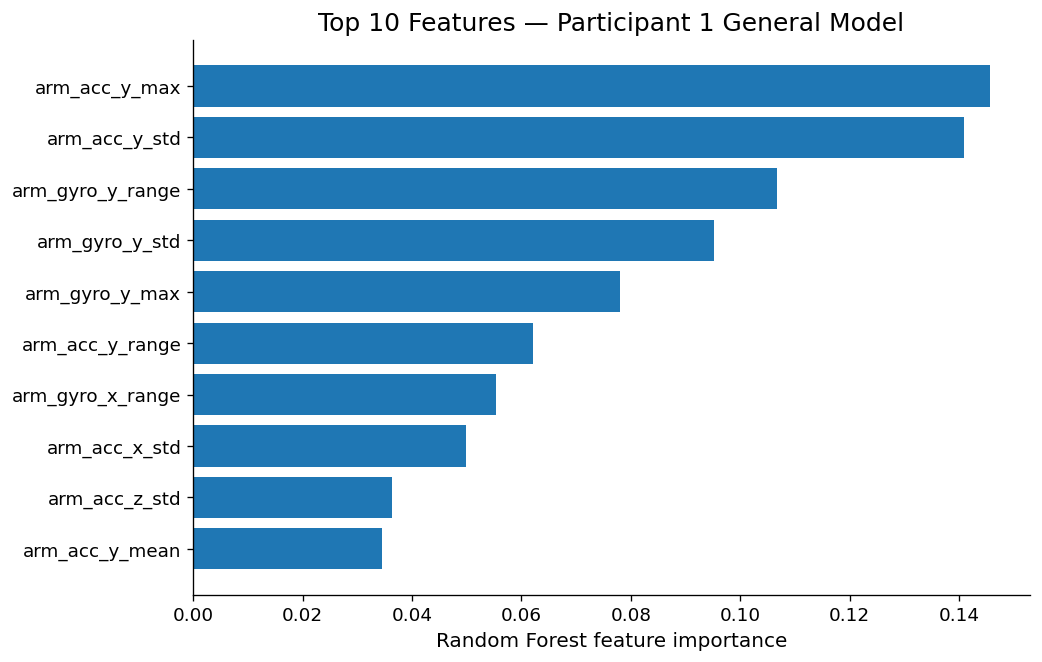

In [49]:
importance_df = pd.DataFrame({
    "Feature": general_model.feature_names_in_,
    "Importance": general_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).head(10)

importance_df = importance_df.sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

ax.set_xlabel("Random Forest feature importance")
ax.set_title("Top 10 Features — Participant 1 General Model")

plt.savefig(
    f"{FIGURE_FOLDER}/figure_6_feature_importance.png",
    bbox_inches="tight"
)

plt.show()

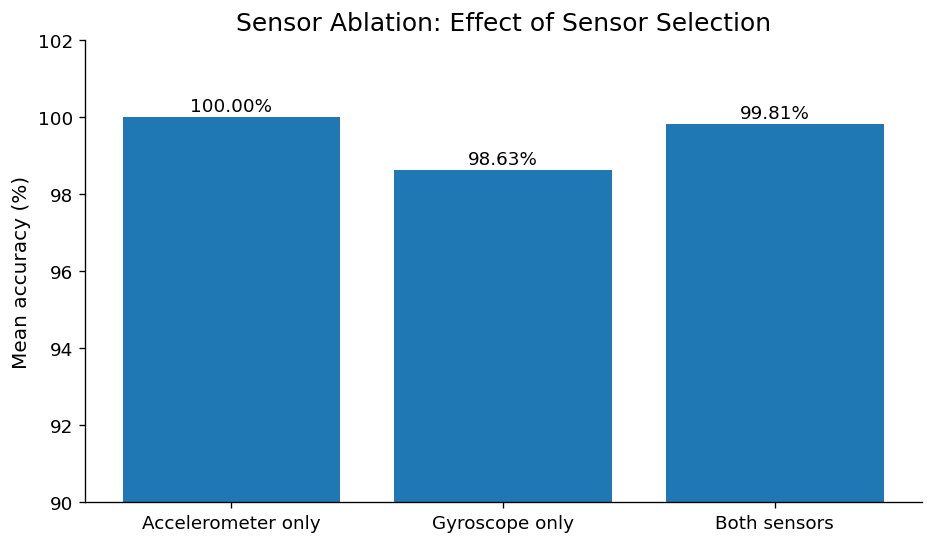

In [52]:
sensor_results = pd.DataFrame({
    "Sensor configuration": [
        "Accelerometer only",
        "Gyroscope only",
        "Both sensors"
    ],
    "Accuracy": [
        100.000,
        98.631,
        99.815
    ]
})

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    sensor_results["Sensor configuration"],
    sensor_results["Accuracy"]
)

ax.set_ylim(90, 102)
ax.set_ylabel("Mean accuracy (%)")
ax.set_title("Sensor Ablation: Effect of Sensor Selection")

for bar, value in zip(bars, sensor_results["Accuracy"]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center"
    )

plt.savefig(
    f"{FIGURE_FOLDER}/figure_8_sensor_ablation.png",
    bbox_inches="tight"
)

plt.show()

In [53]:
import shutil

shutil.make_archive(
    "/content/research_figures",
    "zip",
    FIGURE_FOLDER
)

print("All figures saved and compressed.")

All figures saved and compressed.
